**Bioinformatics Analysis of Human Angiotensin-Converting Enzyme (ACE) Gene using Python and Biopython**

1. Introduction

The Angiotensin-Converting Enzyme (ACE) gene plays an important role in the human body, particularly in the regulation of blood pressure. It provides instructions for producing an enzyme involved in the renin–angiotensin system, which helps maintain blood pressure and fluid balance.

The human ACE gene is located on chromosome 17. Studying its DNA sequence can help us understand its genetic organisation and the relationship between its nucleotide sequence and the protein it produces.

In this project, I used Python and the Biopython library to retrieve and analyse the human ACE gene sequence from the NCBI database. I examined its nucleotide composition, calculated GC and AT percentages, identified the coding DNA sequence (CDS), and translated the coding sequence into a protein sequence.

I also compared the translated protein with the reference protein available in NCBI to check whether both sequences matched. Finally, I used a bar graph to present the nucleotide composition in a simple visual format.

2. Objectives

The main objectives of this project were:

- To retrieve the human ACE gene reference sequence from the NCBI database.
- To examine the number of adenine, thymine, guanine and cytosine bases in the sequence.
- To calculate the GC and AT content.
- To identify and extract the coding DNA sequence of the ACE gene.
- To translate the coding sequence into its corresponding protein sequence.
- To compare the translated protein with the NCBI reference protein.
- To represent the nucleotide composition using a graphical method.

3. Tools and Resources

The following tools and resources were used during the analysis:

- Python – for sequence analysis and calculations.
- Google Colab – to write and execute Python code.
- Biopython – for retrieving and analysing biological sequences.
- NCBI Nucleotide – as the source of the reference DNA sequence.
- Matplotlib – to generate the nucleotide composition graph.

4. Sequence Information

The reference sequence used for this analysis was obtained from the NCBI Nucleotide database.

- Gene: ACE (Angiotensin-Converting Enzyme)
- Organism: Homo sapiens
- Accession number: NG_011648.1
- Sequence length: 27,546 bp
- Protein accession: NP_000780.1

5. Materials and Methods

5.1 Retrieval of the ACE Gene Sequence

The human ACE gene reference sequence was obtained from the NCBI Nucleotide database using its accession number, NG_011648.1. I used the Biopython Entrez module to retrieve the sequence in GenBank format. The SeqIO module was then used to read the downloaded record and access its sequence details and annotations.

5.2 Identification of the Coding Sequence

After retrieving the GenBank record, I examined its annotated features to identify the coding DNA sequence (CDS) associated with the ACE gene. The CDS was extracted using the feature annotation available in the record.

5.3 Protein Translation and Validation

The extracted coding sequence was translated into an amino acid sequence using the standard genetic code. The resulting protein sequence was compared with the annotated reference protein provided in the NCBI record to check whether the translation matched.

5.4 Nucleotide Composition Analysis

The retrieved DNA sequence was analysed to determine the number of adenine (A), thymine (T), guanine (G) and cytosine (C) nucleotides. Python's Counter function was used to count each nucleotide.

GC and AT percentages were calculated using the following formulas:

GC content:

GC% = [(G + C) / Total number of nucleotides] × 100

AT content:

AT% = [(A + T) / Total number of nucleotides] × 100

5.5 Graphical Representation

Matplotlib was used to create a bar graph showing the number of A, T, G and C nucleotides in the human ACE reference sequence. This graph helped present the nucleotide composition in a visual format.

In [19]:
!pip install biopython

from Bio import Entrez, SeqIO
from collections import Counter

Entrez.email = "kamaruthusanjeevasruthi300401@gmail.com"

accession = "NG_011648.1"

handle = Entrez.efetch(
    db="nucleotide",
    id=accession,
    rettype="gb",
    retmode="text"
)

record = SeqIO.read(handle, "genbank")
handle.close()

print("ACCESSION:", record.id)
print("DESCRIPTION:", record.description)
print("SEQUENCE LENGTH:", len(record.seq), "bp")

print("\nFEATURE TYPES:")
print(Counter(feature.type for feature in record.features))

print("\nGENE AND CDS ANNOTATIONS:")

for feature in record.features:
    if feature.type in ["gene", "CDS"]:
        print("\nFeature:", feature.type)
        print("Location:", feature.location)
        print("Details:", feature.qualifiers)

ACCESSION: NG_011648.1
DESCRIPTION: Homo sapiens angiotensin I converting enzyme (ACE), RefSeqGene on chromosome 17
SEQUENCE LENGTH: 27546 bp

FEATURE TYPES:
Counter({'misc_feature': 27, 'exon': 25, 'gene': 2, 'mat_peptide': 2, 'source': 1, 'mRNA': 1, 'CDS': 1, 'sig_peptide': 1})

GENE AND CDS ANNOTATIONS:

Feature: gene
Location: [<0:230](+)
Details: {'gene': ['PPIAP55'], 'note': ['peptidylprolyl isomerase A pseudogene 55'], 'pseudo': [''], 'db_xref': ['GeneID:342541', 'HGNC:HGNC:53679']}

Feature: gene
Location: [4988:26301](+)
Details: {'gene': ['ACE'], 'gene_synonym': ['ACE1; CD143; DCP; DCP1'], 'note': ['angiotensin I converting enzyme'], 'db_xref': ['GeneID:1636', 'HGNC:HGNC:2707', 'MIM:106180']}

Feature: CDS
Location: join{[5022:5271](+), [5858:6026](+), [6934:7028](+), [7696:7840](+), [8264:8456](+), [9018:9116](+), [9493:9666](+), [10393:10617](+), [10956:11101](+), [11387:11486](+), [11776:11899](+), [12257:12469](+), [13163:13300](+), [14484:14643](+), [14913:15001](+), [16

In [20]:
cds_features = [feature for feature in record.features if feature.type == "CDS" and "ACE" in feature.qualifiers.get("gene", [])]
cds_feature = cds_features[0]
cds_sequence = cds_feature.extract(record.seq)
protein_sequence = cds_sequence.translate(table=1)
ncbi_protein = cds_feature.qualifiers["translation"][0]
print("ACE CDS LENGTH:", len(cds_sequence), "bp")
print("PROTEIN LENGTH:", len(ncbi_protein), "amino acids")
print("\nPROTEIN ID:")
print(cds_feature.qualifiers["protein_id"][0])
print("\nTRANSLATED PROTEIN:")
print(protein_sequence)
print("\nPROTEIN MATCH WITH NCBI:")
print(str(protein_sequence).rstrip("*") == ncbi_protein)

ACE CDS LENGTH: 3921 bp
PROTEIN LENGTH: 1306 amino acids

PROTEIN ID:
NP_000780.1

TRANSLATED PROTEIN:
MGAASGRRGPGLLLPLPLLLLLPPQPALALDPGLQPGNFSADEAGAQLFAQSYNSSAEQVLFQSVAASWAHDTNITAENARRQEEAALLSQEFAEAWGQKAKELYEPIWQNFTDPQLRRIIGAVRTLGSANLPLAKRQQYNALLSNMSRIYSTAKVCLPNKTATCWSLDPDLTNILASSRSYAMLLFAWEGWHNAAGIPLKPLYEDFTALSNEAYKQDGFTDTGAYWRSWYNSPTFEDDLEHLYQQLEPLYLNLHAFVRRALHRRYGDRYINLRGPIPAHLLGDMWAQSWENIYDMVVPFPDKPNLDVTSTMLQQGWNATHMFRVAEEFFTSLELSPMPPEFWEGSMLEKPADGREVVCHASAWDFYNRKDFRIKQCTRVTMDQLSTVHHEMGHIQYYLQYKDLPVSLRRGANPGFHEAIGDVLALSVSTPEHLHKIGLLDRVTNDTESDINYLLKMALEKIAFLPFGYLVDQWRWGVFSGRTPPSRYNFDWWYLRTKYQGICPPVTRNETHFDAGAKFHVPNVTPYIRYFVSFVLQFQFHEALCKEAGYEGPLHQCDIYRSTKAGAKLRKVLQAGSSRPWQEVLKDMVGLDALDAQPLLKYFQPVTQWLQEQNQQNGEVLGWPEYQWHPPLPDNYPEGIDLVTDEAEASKFVEEYDRTSQVVWNEYAEANWNYNTNITTETSKILLQKNMQIANHTLKYGTQARKFDVNQLQNTTIKRIIKKVQDLERAALPAQELEEYNKILLDMETTYSVATVCHPNGSCLQLEPDLTNVMATSRKYEDLLWAWEGWRDKAGRAILQFYPKYVELINQAARLNGYVDAGDSWRSMYETPSLEQDLERLFQELQPLYLNLHAYVRRALHRHYGAQHINLEGPIPAHLLGNMWAQTWSNIYDLVVP

In [21]:
from collections import Counter

dna = str(record.seq).upper()
base_counts = Counter(dna)

total_length = len(dna)

A_count = base_counts["A"]
T_count = base_counts["T"]
G_count = base_counts["G"]
C_count = base_counts["C"]

gc_content = ((G_count + C_count) / total_length) * 100
at_content = ((A_count + T_count) / total_length) * 100

print("ACE GENE ANALYSIS")
print("Total length:", total_length)
print("A count:", A_count)
print("T count:", T_count)
print("G count:", G_count)
print("C count:", C_count)
print("GC content:", gc_content)
print("AT content:", at_content)

ACE GENE ANALYSIS
Total length: 27546
A count: 5872
T count: 6009
G count: 7535
C count: 8130
GC content: 56.868510854570545
AT content: 43.13148914542946


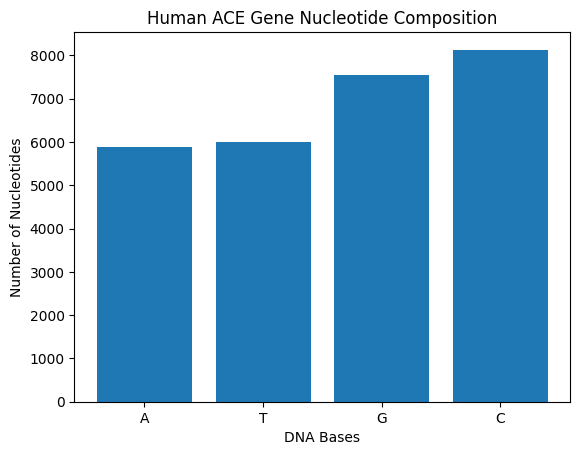

In [22]:
import matplotlib.pyplot as plt

bases = ["A", "T", "G", "C"]
counts = [5872, 6009, 7535, 8130]

plt.bar(bases, counts)

plt.title("Human ACE Gene Nucleotide Composition")
plt.xlabel("DNA Bases")
plt.ylabel("Number of Nucleotides")

plt.show()

6. Results

6.1 Retrieval of the Human ACE Gene Sequence

The human ACE reference gene sequence was successfully retrieved from the NCBI Nucleotide database using Biopython.

The retrieved genomic reference sequence had a total length of 27,546 base pairs (bp).

6.2 Coding Sequence and Protein Translation

The annotated coding DNA sequence (CDS) of the ACE gene was successfully extracted from the GenBank record.

- CDS length: 3,291 bp
- Reference protein accession: NP_000780.1
- Reference protein length: 1,306 amino acids
- Translation comparison with the NCBI reference protein: True

The translated sequence matched the annotated NCBI protein sequence after excluding the terminal stop symbol.

6.3 Nucleotide Composition Analysis

The nucleotide composition of the retrieved ACE genomic reference sequence was analysed.

The results were:

DNA base| Number of nucleotides
Adenine (A)| 5,872
Thymine (T)| 6,009
Guanine (G)| 7,535
Cytosine (C)| 8,130
Total| 27,546

6.4 GC and AT Content

The GC and AT percentages were calculated using the nucleotide counts.

- GC content: 56.87%
- AT content: 43.13%

The results show that guanine and cytosine together account for approximately 56.87% of the analysed sequence, while adenine and thymine account for 43.13%.

6.5 Graphical Representation

A bar graph was generated using Matplotlib to display the number of adenine, thymine, guanine and cytosine nucleotides in the ACE reference sequence.

The graph provides a visual comparison of the four nucleotide counts. Cytosine had the highest count, followed by guanine, thymine and adenine.

7. Discussion

In this project, I analysed the human ACE gene reference sequence using Python and Biopython. The sequence was retrieved successfully from the NCBI Nucleotide database, and its nucleotide composition was examined.

The analysis showed that the reference sequence contained 27,546 base pairs. Among the four DNA nucleotides, cytosine had the highest count, followed by guanine, thymine and adenine.

The calculated GC content was 56.87%, while the AT content was 43.13%. This indicates that the analysed genomic sequence contained a higher proportion of guanine and cytosine bases than adenine and thymine bases.

I also extracted the annotated coding DNA sequence and translated it into a protein sequence. The translated sequence matched the protein annotation available in the NCBI record after excluding the terminal stop symbol. This provided a useful validation of the translation process.

The bar graph made it easier to compare the nucleotide counts visually. Overall, this project helped me understand how biological sequence data can be retrieved, processed and analysed using Python-based bioinformatics tools.

8. Conclusion

This project provided practical experience in analysing the human ACE gene reference sequence using Python and Biopython.

I successfully retrieved the sequence from NCBI, examined its nucleotide composition, calculated GC and AT content, extracted the coding sequence and translated it into a protein sequence.

The comparison with the NCBI reference protein confirmed that the translated sequence matched the annotated protein. The nucleotide composition was also represented using a bar graph.

Through this work, I gained a better understanding of biological sequence analysis, protein translation and the use of computational tools in bioinformatics research.

9. References

1. National Center for Biotechnology Information (NCBI). Homo sapiens angiotensin I converting enzyme (ACE), RefSeqGene sequence. Accession number: NG_011648.1. Available at: https://www.ncbi.nlm.nih.gov/nuccore/NG_011648.1

2. National Center for Biotechnology Information (NCBI). Angiotensin-converting enzyme isoform 1 precursor. Protein accession number: NP_000780.1. Available at: https://www.ncbi.nlm.nih.gov/protein/NP_000780.1

3. Cock, P. J. A., Antao, T., Chang, J. T., et al. (2009). Biopython: freely available Python tools for computational molecular biology and bioinformatics. Bioinformatics, 25(11), 1422–1423. https://doi.org/10.1093/bioinformatics/btp163

4. Biopython Documentation. Available at: https://biopython.org/wiki/Documentation

5. Matplotlib Documentation. Available at: https://matplotlib.org/stable/